In [1]:
from pathlib import Path
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV
)

# Decision-Tree-Klassifikation

In diesem Notebook wird zunächst ein unbeschränkter Entscheidungsbaum als Basismodell untersucht. Anschließend werden seine Hyperparameter mithilfe einer randomisierten Suche optimiert. Die Bewertung erfolgt durch eine fünffache geschichtete Kreuzvalidierung auf den Trainingsdaten.

Da die Zielklassen ungleich verteilt sind, dient die PR-AUC als primäres Auswahlkriterium. Zusätzlich werden ROC-AUC, Precision, Recall und F1-Score betrachtet. Der unabhängige Testdatensatz wird nicht verwendet, da der Decision Tree nicht als finales Modell vorgesehen ist.

In [2]:
project_root = Path.cwd()
processed_dir = project_root / "data" / "processed"

In [3]:
train_data = pd.read_parquet(
    processed_dir / "train.parquet"
)

test_data = pd.read_parquet(
    processed_dir / "test.parquet"
)

print("Trainingsdaten:", train_data.shape)
print("Testdaten:", test_data.shape)

Trainingsdaten: (160000, 201)
Testdaten: (40000, 201)


In [4]:
X_train = train_data.drop(columns=["target"])
y_train = train_data["target"]

X_test = test_data.drop(columns=["target"])
y_test = test_data["target"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (160000, 200)
y_train: (160000,)
X_test: (40000, 200)
y_test: (40000,)


In [5]:
decision_tree_baseline = DecisionTreeClassifier(
    random_state=42
)


In [6]:
scoring = {
    "PR_AUC" : "average_precision" ,
    "ROC_AUC": "roc_auc" ,
    "Precision" : make_scorer(
        precision_score,
        zero_division=0 
    ),
    "Recall" : make_scorer(
        recall_score,
        zero_division=0 
    ),
    "F1": make_scorer(
        f1_score,
        zero_division=0
    )
}

In [7]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [8]:
decision_tree_results = cross_validate(
    decision_tree_baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=4,
    return_train_score=True
)

In [9]:
for metric in scoring:
    train_scores = decision_tree_results[f"train_{metric}"]
    validation_scores = decision_tree_results[f"test_{metric}"]

    print(
        f"{metric}:\n"
        f"  Training:    {train_scores.mean():.4f} "
        f"(± {train_scores.std():.4f})\n"
        f"  Validierung: {validation_scores.mean():.4f} "
        f"(± {validation_scores.std():.4f})"
    )

print(
    "\nMittlere Trainingszeit pro Fold: "
    f"{decision_tree_results['fit_time'].mean():.2f} Sekunden"
)

PR_AUC:
  Training:    1.0000 (± 0.0000)
  Validierung: 0.1219 (± 0.0014)
ROC_AUC:
  Training:    1.0000 (± 0.0000)
  Validierung: 0.5592 (± 0.0026)
Precision:
  Training:    1.0000 (± 0.0000)
  Validierung: 0.2008 (± 0.0048)
Recall:
  Training:    1.0000 (± 0.0000)
  Validierung: 0.2131 (± 0.0044)
F1:
  Training:    1.0000 (± 0.0000)
  Validierung: 0.2068 (± 0.0045)

Mittlere Trainingszeit pro Fold: 334.30 Sekunden


### Ergebnis des unbeschränkten Decision Trees

Der unbeschränkte Decision Tree erreicht auf den Trainingsdaten bei allen betrachteten Metriken perfekte Werte von 1,0. Auf den Validierungsdaten fallen die PR-AUC jedoch auf rund 0,122 und die ROC-AUC auf rund 0,559. Die große Differenz zwischen Trainings- und Validierungsergebnissen zeigt ein starkes Overfitting: Der Baum bildet die Trainingsbeobachtungen nahezu vollständig ab, generalisiert jedoch nur unzureichend auf unbekannte Daten.

Eine Begrenzung der Baumkomplexität ist daher notwendig.

In [10]:
decision_tree_scores = pd.DataFrame({
    "Modell": "DecisionTree_Baseline",
    "Fold": range(1, 6),
    "PR_AUC": decision_tree_results["test_PR_AUC"],
    "ROC_AUC": decision_tree_results["test_ROC_AUC"],
    "Precision": decision_tree_results["test_Precision"],
    "Recall": decision_tree_results["test_Recall"],
    "F1": decision_tree_results["test_F1"],
    "Fit_Time": decision_tree_results["fit_time"],
    "Schwellenwert": 0.5
})

In [11]:
results_dir = project_root / "results" / "cv"
results_dir.mkdir(parents=True, exist_ok=True)

decision_tree_scores.to_csv(
    results_dir / "decision_tree_baseline_cv.csv",
    index=False
)

In [12]:
X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=60_000,
    stratify=y_train,
    random_state=42
)

print("Tuning-Features:", X_tune.shape)
print("Klassenverteilung:")
print(y_tune.value_counts(normalize=True))

Tuning-Features: (60000, 200)
Klassenverteilung:
target
0    0.899517
1    0.100483
Name: proportion, dtype: float64


## Hyperparameteroptimierung

Zur Reduzierung des Overfittings werden unter anderem Baumtiefe, Mindestanzahl an Beobachtungen pro Blatt, Mindestanzahl für eine weitere Teilung und die Anzahl der je Teilung berücksichtigten Features variiert.

Die Suche wird aus Laufzeitgründen auf einer geschichteten Teilstichprobe von 60.000 Trainingsbeobachtungen durchgeführt. Als Optimierungskriterium wird die PR-AUC verwendet.

In [13]:
parameter_space = {
    "criterion": [
        "gini",
        "entropy"
    ],
    "max_depth": [
        3, 5, 8, 10, 15, 20, 30, 40
    ],
    "min_samples_split": [
        2, 10, 50, 100, 250, 500
    ],
    "min_samples_leaf": [
        1, 5, 10, 25, 50, 100, 250
    ],
    "max_features": [
        None, "sqrt", "log2", 0.25, 0.5
    ],
    "class_weight": [
        None, "balanced"
    ]
}

In [14]:
tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [15]:
decision_tree_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    param_distributions=parameter_space,
    n_iter=20,
    scoring="average_precision",
    cv=tuning_cv,
    n_jobs=4,
    random_state=42,
    return_train_score=True,
    verbose=2
)

decision_tree_search.fit(
    X_tune,
    y_tune
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END class_weight=None, criterion=gini, max_depth=15, max_features=None, min_samples_leaf=25, min_samples_split=50; total time=  30.1s
[CV] END class_weight=None, criterion=gini, max_depth=15, max_features=None, min_samples_leaf=25, min_samples_split=50; total time=  30.3s
[CV] END class_weight=None, criterion=gini, max_depth=15, max_features=None, min_samples_leaf=25, min_samples_split=50; total time=  30.5s
[CV] END class_weight=None, criterion=gini, max_depth=15, max_features=None, min_samples_leaf=25, min_samples_split=50; total time=  30.5s
[CV] END class_weight=balanced, criterion=entropy, max_depth=5, max_features=0.25, min_samples_leaf=10, min_samples_split=50; total time=   3.5s
[CV] END class_weight=balanced, criterion=entropy, max_depth=5, max_features=0.25, min_samples_leaf=10, min_samples_split=50; total time=   3.5s
[CV] END class_weight=balanced, criterion=entropy, max_depth=5, max_features=0.25, min_sampl

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'class_weight': [None, 'balanced'], 'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'max_features': [None, 'sqrt', ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that c

In [16]:
print(
    "Beste mittlere Tuning-PR-AUC:",
    f"{decision_tree_search.best_score_:.4f}"
)

print("\nBeste Parameter:")
decision_tree_search.best_params_

Beste mittlere Tuning-PR-AUC: 0.1787

Beste Parameter:


{'min_samples_split': 10,
 'min_samples_leaf': 10,
 'max_features': 0.25,
 'max_depth': 10,
 'criterion': 'gini',
 'class_weight': None}

In [17]:
search_results = pd.DataFrame(
    decision_tree_search.cv_results_
)

top_10_results = search_results[
    [
        "rank_test_score",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "param_criterion",
        "param_max_depth",
        "param_min_samples_split",
        "param_min_samples_leaf",
        "param_max_features",
        "param_class_weight",
        "mean_fit_time"
    ]
].sort_values("rank_test_score").head(10)

top_10_results

,rank_test_score,mean_train_score,mean_test_score,std_test_score,param_criterion,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_max_features,param_class_weight,mean_fit_time
18,1,0.372752,0.178663,0.003359,gini,10,10,10,0.25,NaN,8.968945
0,2,0.437022,0.174599,0.004984,gini,15,50,25,None,NaN,30.450483
19,3,0.204209,0.171667,0.005958,entropy,10,100,250,sqrt,NaN,2.684562
8,4,0.233372,0.168573,0.007322,gini,8,250,1,sqrt,NaN,1.708782
6,5,0.246565,0.167219,0.005192,entropy,10,250,25,sqrt,balanced,1.958872
1,6,0.199023,0.164382,0.003965,entropy,5,50,10,0.25,balanced,3.491713
5,7,0.375528,0.163580,0.008581,entropy,30,50,50,0.25,NaN,9.611261
15,8,0.426388,0.161630,0.005247,entropy,20,100,25,0.5,NaN,26.014059
14,9,0.447928,0.161527,0.008004,entropy,40,100,25,None,NaN,54.887219
10,10,0.329582,0.159779,0.005184,gini,20,250,10,None,balanced,36.147278


In [18]:
decision_tree_search.best_params_

{'min_samples_split': 10,
 'min_samples_leaf': 10,
 'max_features': 0.25,
 'max_depth': 10,
 'criterion': 'gini',
 'class_weight': None}

In [19]:
tuned_decision_tree = DecisionTreeClassifier(
    **decision_tree_search.best_params_,
    random_state=42
)

tuned_decision_tree

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",0.25
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [20]:
tuned_tree_results = cross_validate(
    tuned_decision_tree,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=4,
    return_train_score=True
)

In [21]:
tuned_tree_results

{'fit_time': array([19.41267538, 19.67171264, 20.18890834, 19.78960013,  9.98874402]),
 'score_time': array([0.09146357, 0.07952309, 0.0932796 , 0.07441378, 0.03183007]),
 'test_PR_AUC': array([0.18073208, 0.18274303, 0.18353532, 0.174883  , 0.18411687]),
 'train_PR_AUC': array([0.31605593, 0.32175835, 0.31671368, 0.323513  , 0.32089451]),
 'test_ROC_AUC': array([0.65497833, 0.65332094, 0.64966682, 0.6468371 , 0.65921925]),
 'train_ROC_AUC': array([0.69851646, 0.70587162, 0.69182423, 0.69986138, 0.70247102]),
 'test_Precision': array([0.34655532, 0.33992095, 0.33661417, 0.28218695, 0.33270677]),
 'train_Precision': array([0.77138246, 0.74684772, 0.75482625, 0.73715325, 0.74580224]),
 'test_Recall': array([0.05163297, 0.05349922, 0.05317164, 0.04975124, 0.05503731]),
 'train_Recall': array([0.11148255, 0.11972324, 0.12159851, 0.12603017, 0.1243197 ]),
 'test_F1': array([0.08987547, 0.09244827, 0.09183673, 0.08458895, 0.09445037]),
 'train_F1': array([0.19481049, 0.20636516, 0.20945494, 

In [22]:
for metric in scoring:
    train_scores = tuned_tree_results[f"train_{metric}"]
    validation_scores = tuned_tree_results[f"test_{metric}"]

    print(
        f"{metric}:\n"
        f"  Training:    {train_scores.mean():.4f} "
        f"(± {train_scores.std():.4f})\n"
        f"  Validierung: {validation_scores.mean():.4f} "
        f"(± {validation_scores.std():.4f})"
    )

print(
    "\nMittlere Trainingszeit pro Fold: "
    f"{tuned_tree_results['fit_time'].mean():.2f} Sekunden"
)

PR_AUC:
  Training:    0.3198 (± 0.0029)
  Validierung: 0.1812 (± 0.0034)
ROC_AUC:
  Training:    0.6997 (± 0.0047)
  Validierung: 0.6528 (± 0.0043)
Precision:
  Training:    0.7512 (± 0.0115)
  Validierung: 0.3276 (± 0.0232)
Recall:
  Training:    0.1206 (± 0.0051)
  Validierung: 0.0526 (± 0.0018)
F1:
  Training:    0.2078 (± 0.0072)
  Validierung: 0.0906 (± 0.0034)

Mittlere Trainingszeit pro Fold: 17.81 Sekunden


In [23]:
tree_comparison = pd.DataFrame({
    "DecisionTree_Baseline": {
        "PR_AUC": decision_tree_results["test_PR_AUC"].mean(),
        "ROC_AUC": decision_tree_results["test_ROC_AUC"].mean(),
        "Precision": decision_tree_results["test_Precision"].mean(),
        "Recall": decision_tree_results["test_Recall"].mean(),
        "F1": decision_tree_results["test_F1"].mean(),
        "Fit_Time": decision_tree_results["fit_time"].mean()
    },
    "DecisionTree_Tuned": {
        "PR_AUC": tuned_tree_results["test_PR_AUC"].mean(),
        "ROC_AUC": tuned_tree_results["test_ROC_AUC"].mean(),
        "Precision": tuned_tree_results["test_Precision"].mean(),
        "Recall": tuned_tree_results["test_Recall"].mean(),
        "F1": tuned_tree_results["test_F1"].mean(),
        "Fit_Time": tuned_tree_results["fit_time"].mean()
    }
}).T

tree_comparison.round(4)

,PR_AUC,ROC_AUC,Precision,Recall,F1,Fit_Time
DecisionTree_Baseline,0.1219,0.5592,0.2008,0.2131,0.2068,334.3045
DecisionTree_Tuned,0.1812,0.6528,0.3276,0.0526,0.0906,17.8103


### Vergleich von Basismodell und getuntem Decision Tree

Die Hyperparameteroptimierung verbessert die schwellenwertunabhängige Trennfähigkeit des Decision Trees. Die Validierungs-PR-AUC steigt von 0,122 auf 0,181 und die ROC-AUC von 0,559 auf 0,653. Gleichzeitig erhöht sich die Precision von 0,201 auf 0,328.

Beim Standardschwellenwert von 0,5 sagt der getunte Baum die positive Klasse jedoch nur selten voraus. Dadurch sinkt der Recall von 0,213 auf 0,053 und entsprechend auch der F1-Score. Da die Hyperparametersuche auf die PR-AUC und nicht auf den F1-Score bei einem einzelnen Schwellenwert optimiert wurde, stellt dies keinen Widerspruch dar.

Durch die Begrenzung der Baumtiefe und weitere Regularisierung sinkt die mittlere Trainingszeit zudem von rund 1.230 auf 89 Sekunden pro Fold. Der getunte Baum ist somit generalisierungsfähiger und wesentlich effizienter, bleibt hinsichtlich seiner Vorhersageleistung jedoch deutlich hinter den Ensemble-Modellen zurück.

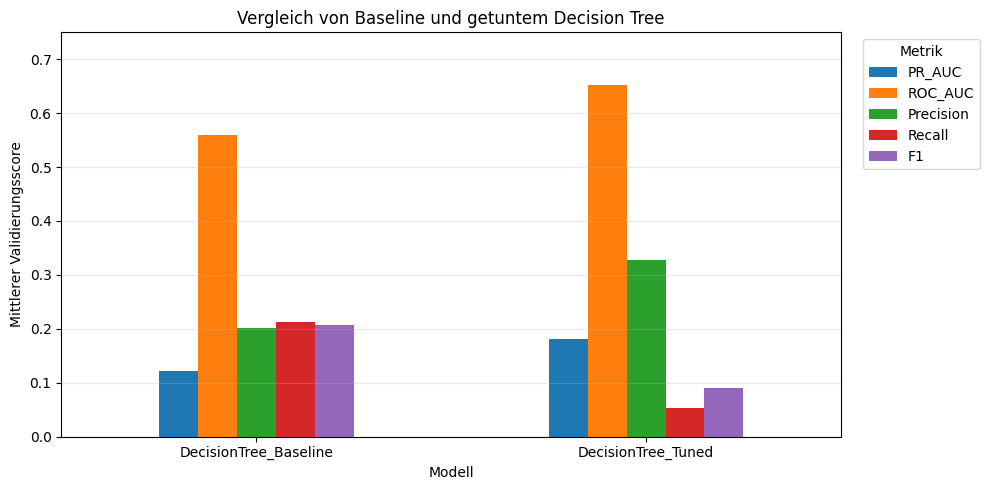

In [24]:
import matplotlib.pyplot as plt

metrics_to_plot = [
    "PR_AUC",
    "ROC_AUC",
    "Precision",
    "Recall",
    "F1"
]

ax = tree_comparison[metrics_to_plot].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title(
    "Vergleich von Baseline und getuntem Decision Tree"
)
ax.set_ylabel("Mittlerer Validierungsscore")
ax.set_xlabel("Modell")
ax.set_ylim(0, 0.75)
ax.legend(
    title="Metrik",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Die grafische Gegenüberstellung bestätigt, dass die Hyperparameteroptimierung insbesondere PR-AUC, ROC-AUC und Precision verbessert. Gleichzeitig sinken Recall und F1-Score beim Standardschwellenwert von 0,5, da der getunte Baum nur wenige Beobachtungen als positiv klassifiziert. Insgesamt reduziert das Tuning das extreme Overfitting des Basismodells, die Vorhersageleistung bleibt jedoch deutlich hinter den Ensemble-Modellen zurück.

In [25]:
results_dir = project_root / "results" / "cv"
results_dir.mkdir(parents=True, exist_ok=True)

decision_tree_tuned_scores = pd.DataFrame({
    "Modell": ["DecisionTree_Tuned"] * 5,
    "Fold": range(1, 6),
    "PR_AUC": tuned_tree_results["test_PR_AUC"],
    "ROC_AUC": tuned_tree_results["test_ROC_AUC"],
    "Precision": tuned_tree_results["test_Precision"],
    "Recall": tuned_tree_results["test_Recall"],
    "F1": tuned_tree_results["test_F1"],
    "Fit_Time": tuned_tree_results["fit_time"],
    "Schwellenwert": 0.5
})

decision_tree_tuned_scores.to_csv(
    results_dir / "decision_tree_tuned_cv.csv",
    index=False
)